In [161]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

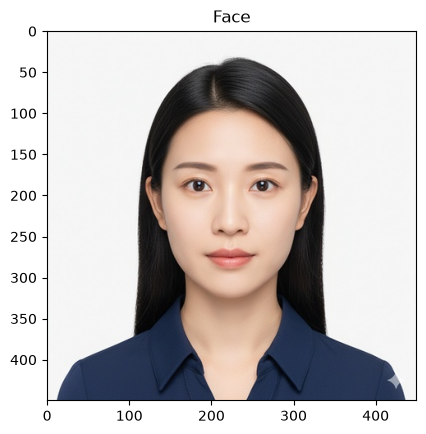

In [162]:
# Load the Face Image
faceImage = cv2.imread('img1.jpg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [163]:
faceImage.shape

(450, 450, 3)

In [164]:
#resized_faceImage.shape
faceImage.shape

(450, 450, 3)

Text(0.5, 1.0, 'glassPNG')

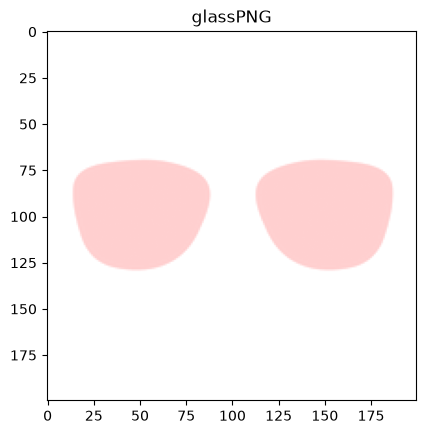

In [165]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('sp.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [166]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(190,50))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(50, 190, 4)


In [167]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

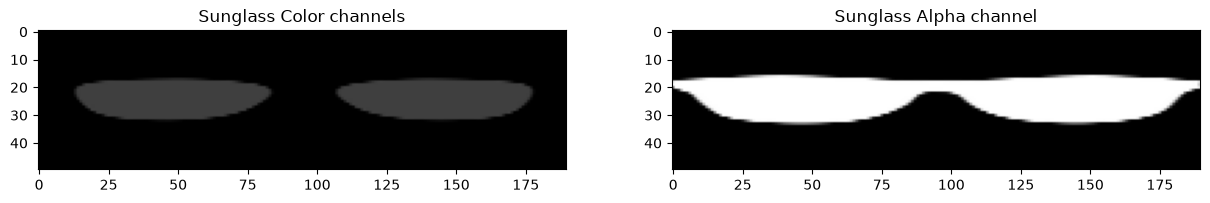

In [168]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

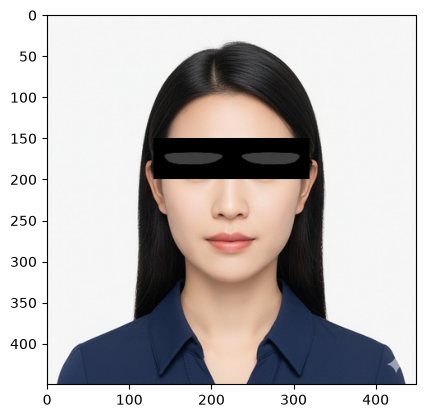

In [174]:
# Make a copy
#faceWithGlassesNaive = resized_faceImage.copy()
faceWithGlassesNaive = faceImage.copy()

# Replace the eye region with the sunglass image
faceWithGlassesNaive[150:200, 130:320] = glassBGR

plt.imshow(faceWithGlassesNaive[...,::-1])

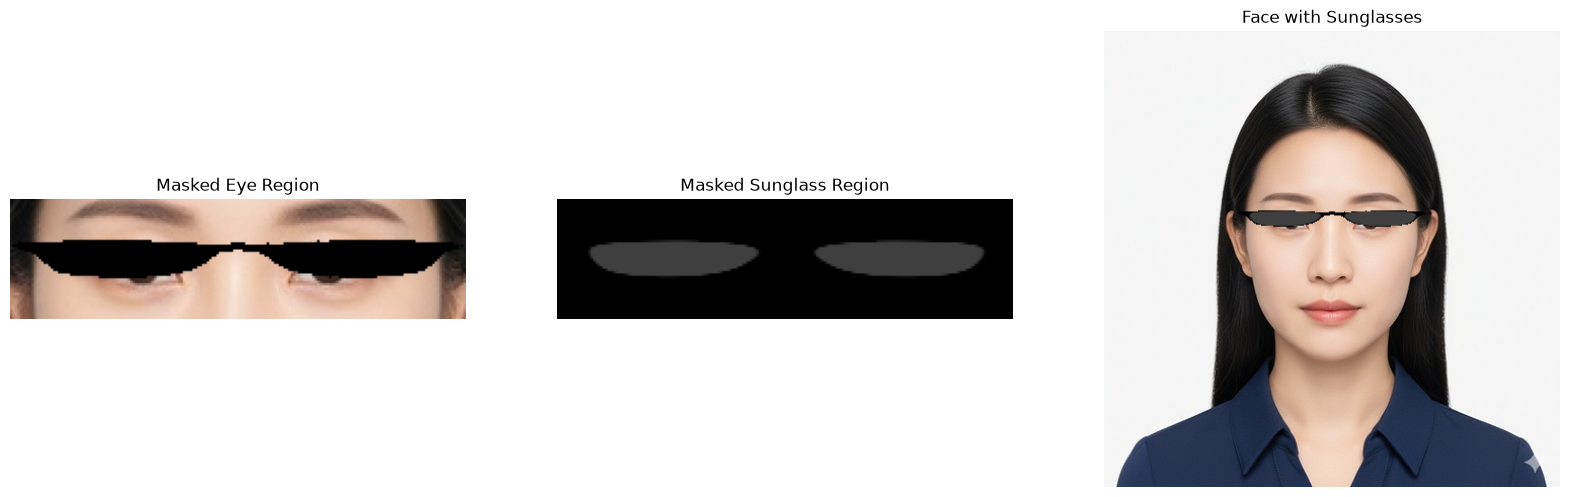

In [178]:

# Make a copy of the original face
faceWithGlassesArithmetic = faceImage.copy()

# Get the eye region (moved 10 pixels down)
eyeROI = faceWithGlassesArithmetic[160:210, 130:320]

# Create masked eye region
maskedEye = cv2.multiply(eyeROI, (1 - glassMask))

# Create masked sunglasses region
maskedGlass = cv2.multiply(glassBGR, glassMask)

# Combine the eye region and sunglasses
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Place the sunglasses onto the face
faceWithGlassesArithmetic[160:210, 130:320] = eyeRoiFinal

# Display results
plt.figure(figsize=[20, 8])

plt.subplot(131)
plt.imshow(maskedEye[:, :, ::-1])
plt.title("Masked Eye Region")
plt.axis("off")

plt.subplot(132)
plt.imshow(maskedGlass[:, :, ::-1])
plt.title("Masked Sunglass Region")
plt.axis("off")

plt.subplot(133)
plt.imshow(faceWithGlassesArithmetic[:, :, ::-1])
plt.title("Face with Sunglasses")
plt.axis("off")

plt.show()



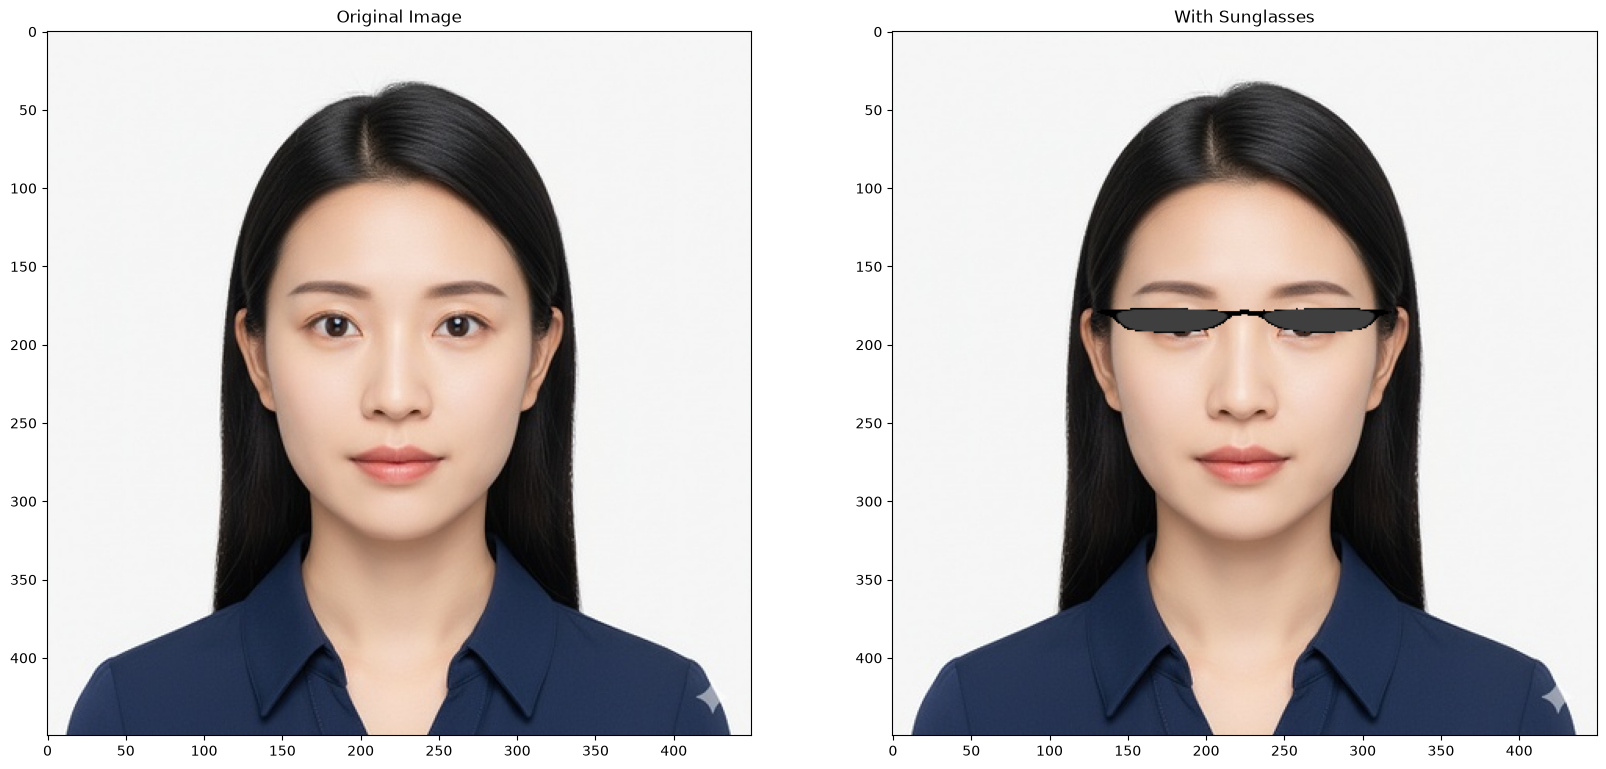

In [180]:
# Replace the eye ROI with the output from the previous section
faceWithGlassesArithmetic = faceImage.copy()
faceWithGlassesArithmetic[160:210, 130:320] = eyeRoiFinal

# Display the final result
plt.figure(figsize=[20, 10])
plt.subplot(121)
plt.imshow(faceImage[:, :, ::-1])
plt.title("Original Image")

plt.subplot(122)
plt.imshow(faceWithGlassesArithmetic[:, :, ::-1])
plt.title("With Sunglasses")

plt.show()